# 05 — Repeated injuries and anatomical transitions

**Objective.** Quantify observed repeat episodes, intervals, same-region recurrence, and pre-injury differences.

**Cohort and interpretation.** Recurrence is among qualifying recorded episodes starting in 2015. A transition requires observed MLB pitching between the two dates; otherwise it is separately flagged and excluded from the transition matrix. First means first observed qualifying episode, not lifetime first injury. Unequal career observation and missing non-IL injuries prevent a causal recurrence-risk interpretation.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


repeat_status
Repeat after observed MLB pitching      2031
First observed qualifying episode       1415
Repeat without observed MLB pitching     106
Name: episodes, dtype: int64

1     584
2     315
3     198
4     116
5      89
6      54
7      12
8      22
9      11
10      7
11      4
12      1
13      2
Name: pitchers_with_n_episodes, dtype: int64

,analysis_group,repeats,pitchers,median_interval_days,same_region_fraction
0,Elbow / UCL,346,265,335.0,0.260116
1,Forearm,152,132,365.5,0.164474
2,Hand / wrist,125,93,325.0,0.240000
3,Lower body,501,331,352.0,0.175649
4,Other arm,128,117,377.5,0.039062
5,Shoulder,449,326,323.0,0.360802
6,Trunk / neck,330,242,381.0,0.160606


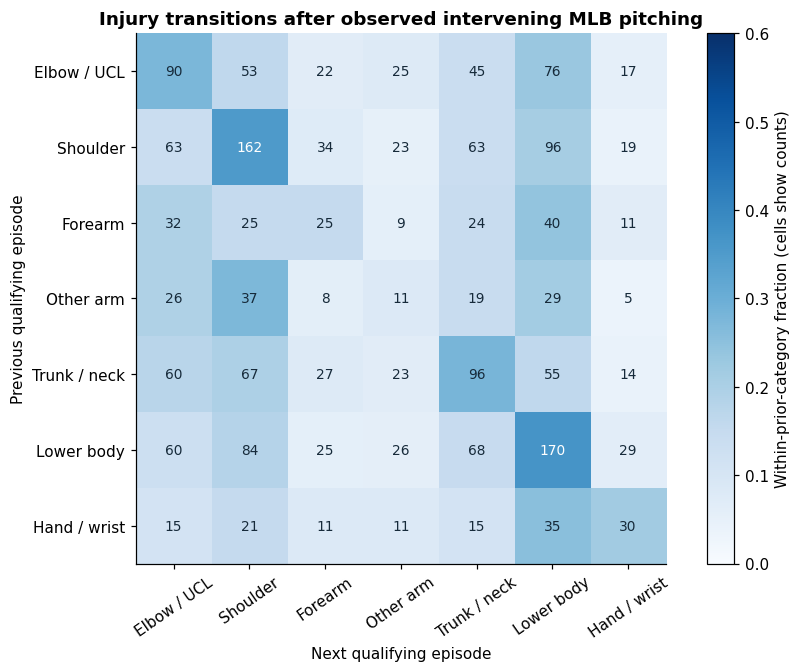

In [2]:
from src.injury_analysis.outcomes import recurrence_analysis
a, events, spec = load()
rec, repeats, transitions, crude = recurrence_analysis(a, events)
display(rec.repeat_status.value_counts().rename('episodes'))
display(rec.groupby('player_id').size().value_counts().sort_index().rename('pitchers_with_n_episodes'))
display(read_table('recurrence_summary'))
plots.recurrence_figure(transitions); plt.show()

## Prior history and warning patterns
The crude appearance rates below use **as-of prior reported IL counts**, never future recurrence rank. Role strata reduce a visible source of confounding, but age, exposure duration and health selection still differ. The first/repeat feature table is descriptive, one mean per event, with pitcher-bootstrap intervals. Outcome-derived episode rank is used only for these comparisons.

In [3]:
display(crude)
patterns=read_table('recurrence_preinjury_features')
display(patterns[patterns.category.isin(['Elbow / UCL','Shoulder','Lower body']) & patterns.feature.eq('velo_z')])
conclusion(f"{len(repeats):,} repeat qualifying episodes have observed intervening MLB pitching. {repeats.same_detailed_region.mean():.1%} involve the same detailed region; the median interval is {repeats.interval_days.median():.0f} days. These transitions establish repeated documented burden, but left truncation, changing observation time and episode-boundary uncertainty prevent interpreting them as clinical recurrence probabilities.")

,prior_episode_band,is_starter,appearances,positive_rows,rate,pitchers
0,0,False,47227,3906,0.082707,1269
1,0,True,11168,1347,0.120612,723
2,1,False,25058,2612,0.104238,744
3,1,True,7531,1005,0.133448,491
4,2–3,False,26597,3129,0.117645,582
5,2–3,True,8195,1330,0.162294,405
6,4+,False,15377,2100,0.136568,306
7,4+,True,8517,1384,0.162499,239


,category,repeat_status,feature,mean,low,high,n,pitchers
0,Elbow / UCL,First observed qualifying episode,velo_z,-0.354242,-0.504360,-0.231878,171,171
4,Elbow / UCL,Repeat after observed MLB pitching,velo_z,-0.378929,-0.498781,-0.258044,276,216
24,Lower body,First observed qualifying episode,velo_z,-0.243819,-0.390278,-0.101786,170,170
28,Lower body,Repeat after observed MLB pitching,velo_z,-0.223801,-0.326079,-0.128205,430,292
40,Shoulder,First observed qualifying episode,velo_z,-0.466146,-0.605061,-0.347800,234,234
44,Shoulder,Repeat after observed MLB pitching,velo_z,-0.517950,-0.617284,-0.395482,347,261


**Computed conclusion.** 2,031 repeat qualifying episodes have observed intervening MLB pitching. 22.3% involve the same detailed region; the median interval is 350 days. These transitions establish repeated documented burden, but left truncation, changing observation time and episode-boundary uncertainty prevent interpreting them as clinical recurrence probabilities.